## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{2}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

In [121]:
import numpy as np
import matplotlib.pyplot as plt

In [122]:
c = np.sqrt(2/np.pi)*np.e**(1/2)

In [123]:
def f(x):
  return (2*(np.exp((-x**2)/2))/np.sqrt(2*np.pi))

In [124]:
def g(x):
  return np.exp(-x)

In [125]:
tentativas = 0
aceitaçao = 0
amostra = []
N = 8000
for i in range(N):
  uni = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while uni*c*g(y) > f(y):
    uni = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
    tentativas += 1
  aceitaçao += 1
  tentativas += 1
  X = y
  amostra.append(X)

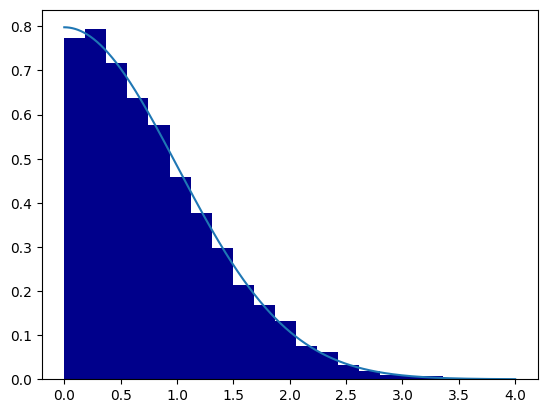

In [126]:
plt.hist(amostra, bins = 20, color = "darkblue", density = True)
x = np.linspace(0,4,1000)
plt.plot(x,f(x))

In [127]:
amostra_normal = []
N = 8000
for i in range(N):
  uni = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while uni*c*g(y) > f(y):
    uni = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  sorteio = np.random.uniform()
  if sorteio > 0.5 :
    X = y
  else:
    X = -y
  amostra_normal.append(X)

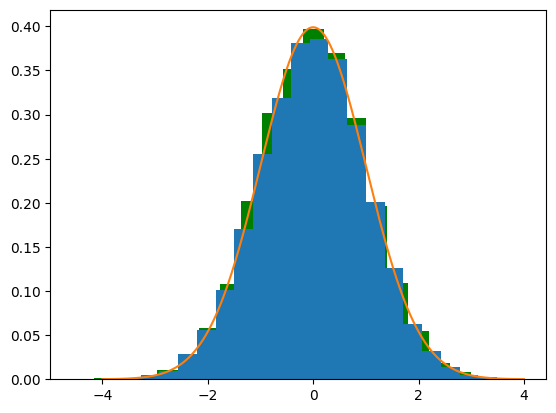

In [128]:
plt.hist(amostra_normal, bins = 20, color = "green",density = True)
plt.hist(np.random.normal(0,1,8000), bins = 20,density = True)
x = np.linspace(-4,4,1000)
plt.plot(x,f(x)/2)

In [129]:
amostra_normal2 = []
N = 8000
sigma = 10
mi = 1
for i in range(N):
  uni = np.random.uniform()
  u = np.random.uniform()
  y = -np.log(1-u)
  while uni*c*g(y) > f(y):
    uni = np.random.uniform()
    u = np.random.uniform()
    y = -np.log(1-u)
  sorteio = np.random.uniform()
  if sorteio > 0.5 :
    X = y
    Z = sigma*X+mi
  else:
    X = -y
    Z = sigma*X+mi
  amostra_normal2.append(Z)

(array([3.02198314e-05, 1.51099157e-04, 4.23077640e-04, 8.76375111e-04,
        3.17308230e-03, 5.71154814e-03, 1.38709026e-02, 2.13049812e-02,
        3.32115947e-02, 3.88022635e-02, 3.92555610e-02, 3.26676378e-02,
        2.42967445e-02, 1.47774976e-02, 7.94781566e-03, 3.20330213e-03,
        1.45055191e-03, 4.23077640e-04, 1.20879326e-04, 6.04396628e-05]),
 array([-40.88447405, -36.74811742, -32.61176079, -28.47540417,
        -24.33904754, -20.20269091, -16.06633428, -11.92997765,
         -7.79362103,  -3.6572644 ,   0.47909223,   4.61544886,
          8.75180549,  12.88816212,  17.02451874,  21.16087537,
         25.297232  ,  29.43358863,  33.56994526,  37.70630188,
         41.84265851]),
 <BarContainer object of 20 artists>)

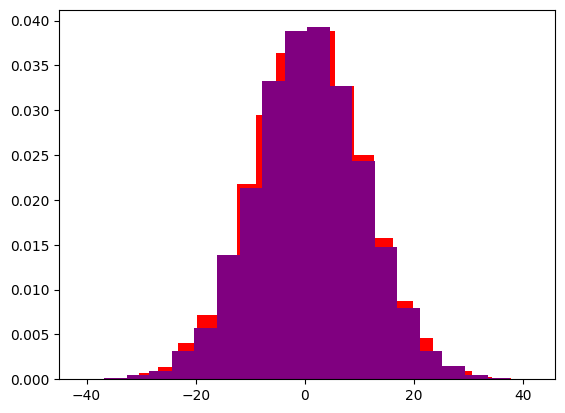

In [130]:
plt.hist(amostra_normal2, bins = 20, color = "red",density = "True")
plt.hist(np.random.normal(1,10,8000),density = True, color = "purple", bins = 20)


In [131]:
p_chapeu = aceitaçao/tentativas
p = 1/c
print(f"p estimado: {p_chapeu} e p teórico: {p}")

p estimado: 0.7671653241273494 e p teórico: 0.7601734505331403
